In [1]:
from pycaret.classification import setup, compare_models, finalize_model, plot_model, save_model, get_config, create_model
from pycaret.datasets import get_data

In [2]:
titanic_df = get_data('titanic')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
len(titanic_df)

891

In [4]:
setup(
    data=titanic_df,
    target='Survived',
    session_id=123,
    ignore_features=['Name', 'Ticket', 'Cabin', 'PassengerId'],
    fix_imbalance=True,
    normalize=True,
    transformation=True,
    n_jobs=1
    )

,Description,Value
0,Session id,123
1,Target,Survived
2,Target type,Binary
3,Original data shape,"(891, 12)"
4,Transformed data shape,"(1036, 10)"
5,Transformed train set shape,"(768, 10)"
6,Transformed test set shape,"(268, 10)"
7,Ignore features,4
8,Numeric features,5
9,Categorical features,2


In [5]:
best_model = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8233,0.8424,0.7236,0.7980,0.7570,0.6190,0.6225,0.1480
lightgbm,Light Gradient Boosting Machine,0.8041,0.8405,0.7237,0.7599,0.7386,0.5824,0.5853,0.0870
ada,Ada Boost Classifier,0.8040,0.8409,0.7824,0.7308,0.7526,0.5912,0.5955,0.1270
rf,Random Forest Classifier,0.7961,0.8415,0.7194,0.7403,0.7289,0.5656,0.5665,0.1650
ridge,Ridge Classifier,0.7944,0.8503,0.7322,0.7342,0.7293,0.5642,0.5681,0.0670
lda,Linear Discriminant Analysis,0.7944,0.8499,0.7322,0.7342,0.7293,0.5642,0.5681,0.0640
et,Extra Trees Classifier,0.7865,0.8279,0.7069,0.7286,0.7155,0.5451,0.5471,0.1510
lr,Logistic Regression,0.7864,0.8515,0.7447,0.7177,0.7255,0.5515,0.5579,0.0690
knn,K Neighbors Classifier,0.7847,0.8314,0.7237,0.7198,0.7207,0.5456,0.5467,0.0680
nb,Naive Bayes,0.7592,0.8276,0.7699,0.6625,0.7087,0.5058,0.5155,0.0670


In [7]:
model = create_model("rf")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8413,0.8750,0.7917,0.7917,0.7917,0.6635,0.6635
1,0.8095,0.8494,0.7500,0.7500,0.7500,0.5962,0.5962
2,0.7778,0.8349,0.6667,0.7273,0.6957,0.5212,0.5224
3,0.7742,0.8818,0.6522,0.7143,0.6818,0.5074,0.5086
4,0.7097,0.7105,0.5833,0.6364,0.6087,0.3786,0.3795
5,0.8065,0.8333,0.7083,0.7727,0.7391,0.5857,0.5871
6,0.9032,0.8904,0.8750,0.8750,0.8750,0.7961,0.7961
7,0.8065,0.8416,0.7500,0.7500,0.7500,0.5921,0.5921
8,0.7419,0.8476,0.6250,0.6818,0.6522,0.4477,0.4487


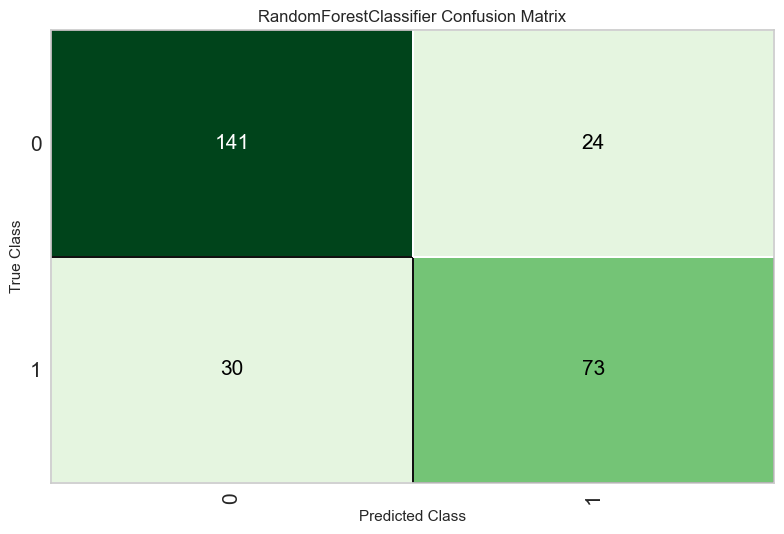

In [8]:
plot_model(model, plot='confusion_matrix')

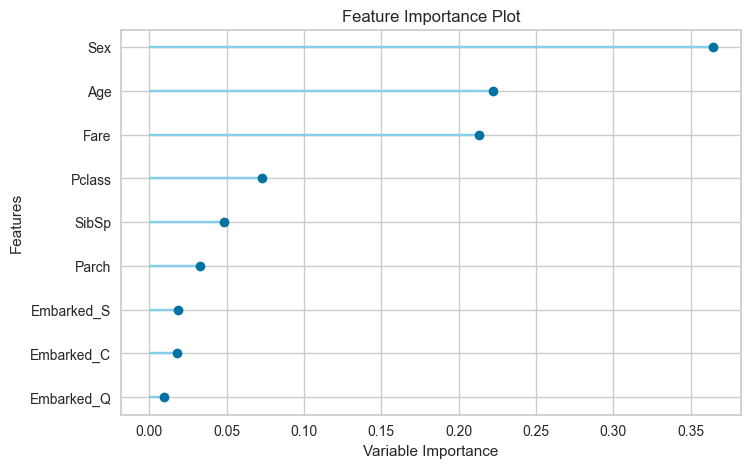

In [9]:
plot_model(model, plot="feature")

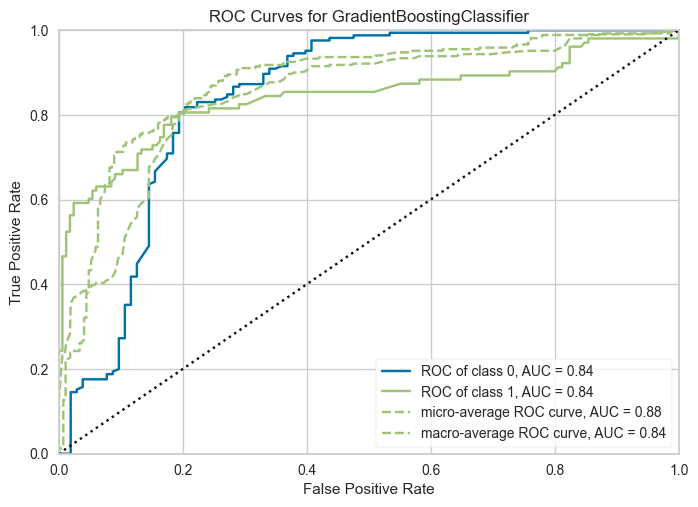

In [10]:
plot_model(best_model, plot='auc')

In [11]:
final_model = finalize_model(best_model)
save_model(finalize_model, 'titanic_classification_pipeline')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Pclass', 'Age', 'SibSp', 'Parch',
                                              'Fare'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 ('categorical_imputer',
                  TransformerWrapper(exclude=None, include=['Sex...
                                                                               sampling_strategy='auto')))),
                 ('tra